In [1]:
###############################################################################################################################################################################################################################################################
### Imports and data upload

In [2]:
import sys
print(sys.executable) # Run the program in the Xenium environment you created

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/bin/python


In [3]:
import scanpy as sc
import pandas as pd
import numpy as np
import h5py
import anndata as ad
import matplotlib.pyplot as plt
import warnings
import os
import squidpy as sq
import spatialdata as sd
import spatialdata_io as sio
import spatialdata_plot
from scipy import sparse
from pathlib import Path
import seaborn as sns

/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/scistore23/sweengrp/sgobeil/venvs/xenium/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from

In [4]:
sc.settings.verbosity = 3

In [5]:
# Done, skip
# !unzip '20260710__125814__MUWCF-LS-999 - Sweeney822893.zip' -d '20260710__125814__MUWCF-LS-999 - Sweeney822893'

In [6]:
# Done, skip
# def saveZarr(filepath, output_name):
#     data = sio.xenium(filepath)
#     # We delete the image as it takes up a lot of memory and we do not use for this analysis guide
#     del data['morphology_focus']
#     data.write(output_name)

# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_1__20260710__125948", 'data_61_Region1.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_2__20260710__125948", 'data_61_Region2.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_3__20260710__125948", 'data_61_Region3.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_4__20260710__125948", 'data_61_Region4.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_5__20260710__125948", 'data_61_Region5.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_6__20260710__125948", 'data_61_Region6.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_7__20260710__125948", 'data_61_Region7.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102261__Region_8__20260710__125948", 'data_61_Region8.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_1__20260710__125947", 'data_60_Region1.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_2__20260710__125948", 'data_60_Region2.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_3__20260710__125948", 'data_60_Region3.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_4__20260710__125948", 'data_60_Region4.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_5__20260710__125948", 'data_60_Region5.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_6__20260710__125948", 'data_60_Region6.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_7__20260710__125948", 'data_60_Region7.zarr')
# saveZarr("20260710__125814__MUWCF-LS-999 - Sweeney822893/20260710__125814__MUWCF-LS-999 - Sweeney/output-XETG00372__0102760__Region_8__20260710__125948", 'data_60_Region8.zarr')

In [7]:
data_61_Region1 = sd.read_zarr("data_61_Region1.zarr")
data_61_Region2 = sd.read_zarr("data_61_Region2.zarr")
data_61_Region3 = sd.read_zarr("data_61_Region3.zarr")
data_61_Region4 = sd.read_zarr("data_61_Region4.zarr")
data_61_Region5 = sd.read_zarr("data_61_Region5.zarr")
data_61_Region6 = sd.read_zarr("data_61_Region6.zarr")
data_61_Region7 = sd.read_zarr("data_61_Region7.zarr")
data_61_Region8 = sd.read_zarr("data_61_Region8.zarr")
data_60_Region1 = sd.read_zarr("data_60_Region1.zarr")
data_60_Region2 = sd.read_zarr("data_60_Region2.zarr")
data_60_Region3 = sd.read_zarr("data_60_Region3.zarr")
data_60_Region4 = sd.read_zarr("data_60_Region4.zarr")
data_60_Region5 = sd.read_zarr("data_60_Region5.zarr")
data_60_Region6 = sd.read_zarr("data_60_Region6.zarr")
data_60_Region7 = sd.read_zarr("data_60_Region7.zarr")
data_60_Region8 = sd.read_zarr("data_60_Region8.zarr")

In [8]:
###############################################################################################################################################################################################################################################################
### Data QC and filtering

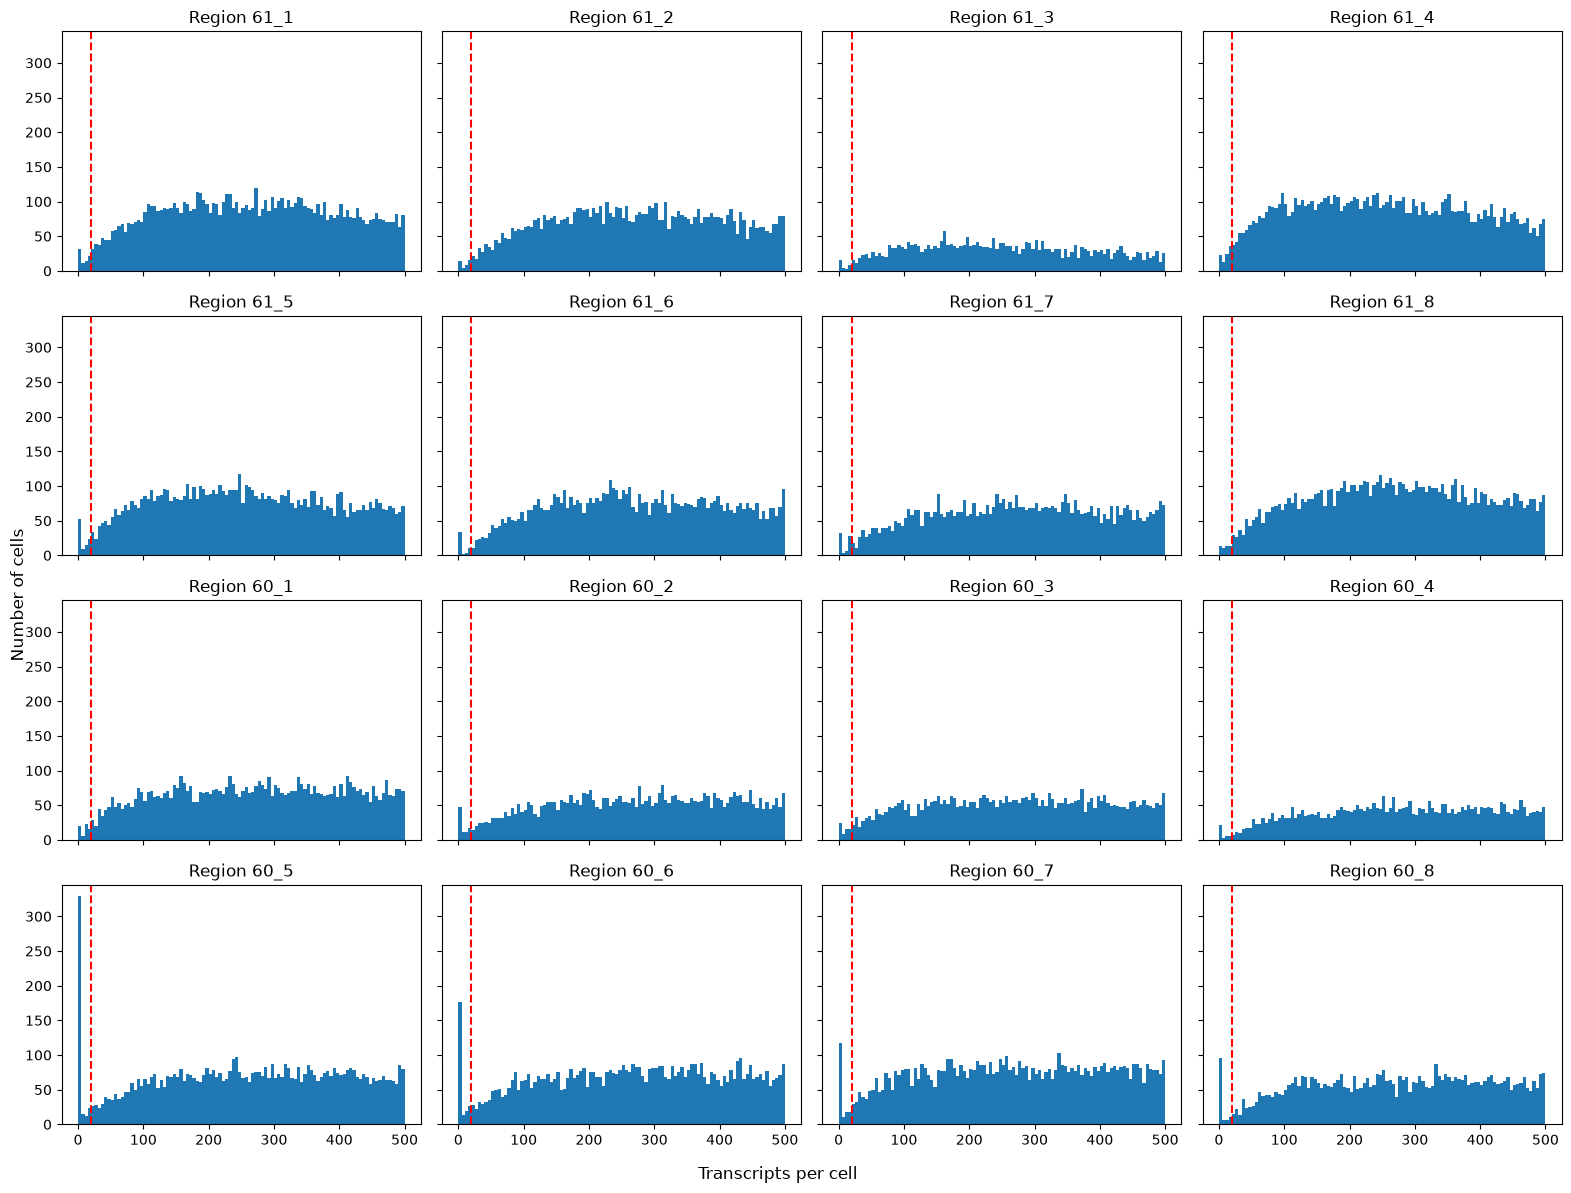

filtered out 79 cells that have less than 20 counts
filtered out 42 cells that have less than 20 counts
filtered out 31 cells that have less than 20 counts
filtered out 98 cells that have less than 20 counts
filtered out 101 cells that have less than 20 counts
filtered out 49 cells that have less than 20 counts
filtered out 73 cells that have less than 20 counts
filtered out 54 cells that have less than 20 counts
filtered out 64 cells that have less than 20 counts
filtered out 88 cells that have less than 20 counts
filtered out 63 cells that have less than 20 counts
filtered out 33 cells that have less than 20 counts
filtered out 379 cells that have less than 20 counts
filtered out 237 cells that have less than 20 counts
filtered out 165 cells that have less than 20 counts
filtered out 119 cells that have less than 20 counts


In [9]:
# QC - low transcript counts
# Note, low quality transcripts (Q-Score ≥ 20) are already filtered out of the data

# Put all 16 SpatialData objects here
datasets = {
    "Region 61_1": data_61_Region1,
    "Region 61_2": data_61_Region2,
    "Region 61_3": data_61_Region3,
    "Region 61_4": data_61_Region4,
    "Region 61_5": data_61_Region5,
    "Region 61_6": data_61_Region6,
    "Region 61_7": data_61_Region7,
    "Region 61_8": data_61_Region8,
    "Region 60_1": data_60_Region1,
    "Region 60_2": data_60_Region2,
    "Region 60_3": data_60_Region3,
    "Region 60_4": data_60_Region4,
    "Region 60_5": data_60_Region5,
    "Region 60_6": data_60_Region6,
    "Region 60_7": data_60_Region7,
    "Region 60_8": data_60_Region8,
}

fig, axes = plt.subplots(
    4, 4,
    figsize=(16, 12),
    sharex=True,
    sharey=True
)

for ax, (name, data) in zip(axes.flat, datasets.items()):
    counts = data["table"].obs["total_counts"]

    ax.hist(
        counts,
        range=(0, 500),
        bins=100
    )

    ax.axvline(20, color="r", linestyle="--")
    ax.set_title(name)

fig.supxlabel("Transcripts per cell")
fig.supylabel("Number of cells")

plt.tight_layout()
plt.show()

### filter out transcripts below a lower and upper cutoff

CUTOFF = 20

for name, data in datasets.items():

    adata = data["table"]

    # Calculate upper cutoff independently for each dataset
    #thresh = np.quantile(adata.obs["total_counts"], 0.98)

    # Save numbers before filtering
    n_cells_before = adata.n_obs
    n_genes_before = adata.n_vars

    # Filter cells
    sc.pp.filter_cells(adata, min_counts=CUTOFF)
    #sc.pp.filter_cells(adata, max_counts=thresh)

    


In [10]:
### load the manually segmented MADM cells.
# Z-stackVisualizer.py was used to the raw transcript counts of custom ROIs and a specified z-volume for MADM cells to minimize transcript mixing due to cell overlap.
# Want to add these cells after filtering, before normalization/scaling. Don't want them to influence clustering/UMAP structure. Instead, they should be used as a query later.

# Get only the actual Xenium region tables
filtered_adatas = [
    data["table"]
    for data in datasets.values()
    if hasattr(data, "shapes")
]

# Find genes retained in ALL Xenium regions
common_genes = filtered_adatas[0].var_names
for a in filtered_adatas[1:]:
    common_genes = common_genes.intersection(a.var_names)

# Metadata for ordinary Xenium cells ONLY
for a in filtered_adatas:
    a.obs["clone"] = "Other cells"
    a.obs["target_cell"] = "Other cells"
    a.obs["source"] = "Xenium"

madm_datasets = {}

### 102760 clone 1
CLONE_NAME = "102760 clone 1"
roi_dir = Path("MADM Cells")

roi_files = {
    "16_0": roi_dir / "16_0_ROI_counts_14-16um.csv",
    "16_1": roi_dir / "16_1_ROI_counts_14-16um.csv",
    "16-2_0": roi_dir / "16-2_0_ROI_counts_13-16um.csv",
    "16-2_1": roi_dir / "16-2_1_ROI_counts_13-17um.csv",
    "16-3_0": roi_dir / "16-3_0_ROI_counts_14-18um.csv",
}

# Build expression matrix for the manually counted MADM cells
madm_expression = []
madm_obs = []

for cell_id, csv_file in roi_files.items():
    df = pd.read_csv(csv_file)
    df["Count"] = pd.to_numeric(df["Count"])

    counts = df.groupby("Gene")["Count"].sum()

    missing_genes = counts.index.difference(common_genes)
    if len(missing_genes) > 0:
        print(f"{cell_id}: {len(missing_genes)} genes excluded/not in filtered dataset")
        print(missing_genes.tolist())

    counts_aligned = counts.reindex(common_genes, fill_value=0)

    madm_expression.append(counts_aligned.to_numpy(dtype=np.float32))

    madm_obs.append({
        "obs_name": f"102760_clone1_{cell_id}",
        "cell_id": cell_id,
        "target_cell": cell_id,
        "clone": CLONE_NAME,
        "source": "manual_ROI_counts",
        "raw_total_counts": counts.sum(),
        "original_file": csv_file.name
    })

# Create AnnData containing the 5 manually counted cells
adata_madm = ad.AnnData(
    X=sparse.csr_matrix(np.vstack(madm_expression)),
    obs=pd.DataFrame(madm_obs).set_index("obs_name"),
    var=pd.DataFrame(index=common_genes)
)

print(adata_madm)
display(adata_madm.obs)

madm_datasets["102760 clone 1"] = adata_madm

print(madm_datasets.keys())

### 102261 clone 1
CLONE_NAME = "102261 clone 1"
roi_dir = Path("MADM Cells")

roi_files = {
    "435_0": roi_dir / "435_0_ROI_counts_18-25um.csv",
    "435_1": roi_dir / "435_1_ROI_counts_12-22um.csv",
    "435_2": roi_dir / "435_2_ROI_counts_12-19um.csv",
    "435_3": roi_dir / "435_3_ROI_counts_22-26um.csv",
    "435_4": roi_dir / "435_4_ROI_counts_20-25um.csv",
    "435_5": roi_dir / "435_5_ROI_counts_15-22um.csv",
    "435_6": roi_dir / "435_6_ROI_counts_13-25um.csv",
}

# Build expression matrix for the manually counted MADM cells
madm_expression = []
madm_obs = []

for cell_id, csv_file in roi_files.items():
    df = pd.read_csv(csv_file)
    df["Count"] = pd.to_numeric(df["Count"])

    counts = df.groupby("Gene")["Count"].sum()

    missing_genes = counts.index.difference(common_genes)
    if len(missing_genes) > 0:
        print(f"{cell_id}: {len(missing_genes)} genes excluded/not in filtered dataset")
        print(missing_genes.tolist())

    counts_aligned = counts.reindex(common_genes, fill_value=0)

    madm_expression.append(counts_aligned.to_numpy(dtype=np.float32))

    madm_obs.append({
        "obs_name": f"102261 clone1_{cell_id}",
        "cell_id": cell_id,
        "target_cell": cell_id,
        "clone": CLONE_NAME,
        "source": "manual_ROI_counts",
        "raw_total_counts": counts.sum(),
        "original_file": csv_file.name
    })

# Create AnnData containing the 5 manually counted cells
adata_madm = ad.AnnData(
    X=sparse.csr_matrix(np.vstack(madm_expression)),
    obs=pd.DataFrame(madm_obs).set_index("obs_name"),
    var=pd.DataFrame(index=common_genes)
)

print(adata_madm)
display(adata_madm.obs)

madm_datasets["102261 clone 1"] = adata_madm

print(madm_datasets.keys())

### 102261 clone 2
CLONE_NAME = "102261 clone 2"
roi_dir = Path("MADM Cells")

roi_files = {
    "443_0": roi_dir / "443_0_ROI_counts_11-16um.csv",
    "443_1": roi_dir / "443_1_ROI_counts_11-19um.csv",
    "443_2": roi_dir / "443_2_ROI_counts_12-19um.csv",
    "443_3": roi_dir / "443_3_ROI_counts_17-23um.csv",
    "445_0": roi_dir / "445_0_ROI_counts_14-19um.csv",
}

# Build expression matrix for the manually counted MADM cells
madm_expression = []
madm_obs = []

for cell_id, csv_file in roi_files.items():
    df = pd.read_csv(csv_file)
    df["Count"] = pd.to_numeric(df["Count"])

    counts = df.groupby("Gene")["Count"].sum()

    missing_genes = counts.index.difference(common_genes)
    if len(missing_genes) > 0:
        print(f"{cell_id}: {len(missing_genes)} genes excluded/not in filtered dataset")
        print(missing_genes.tolist())

    counts_aligned = counts.reindex(common_genes, fill_value=0)

    madm_expression.append(counts_aligned.to_numpy(dtype=np.float32))

    madm_obs.append({
        "obs_name": f"102261 clone2_{cell_id}",
        "cell_id": cell_id,
        "target_cell": cell_id,
        "clone": CLONE_NAME,
        "source": "manual_ROI_counts",
        "raw_total_counts": counts.sum(),
        "original_file": csv_file.name
    })

# Create AnnData containing the 5 manually counted cells
adata_madm = ad.AnnData(
    X=sparse.csr_matrix(np.vstack(madm_expression)),
    obs=pd.DataFrame(madm_obs).set_index("obs_name"),
    var=pd.DataFrame(index=common_genes)
)

print(adata_madm)
display(adata_madm.obs)

madm_datasets["102261 clone 2"] = adata_madm

print(madm_datasets.keys())

### 102760 clone 2
CLONE_NAME = "102760 clone 2"
roi_dir = Path("MADM Cells")

roi_files = {
    "8_0": roi_dir / "8_0_ROI_counts_16-22um.csv",
    "8-3_0": roi_dir / "8-3_0_ROI_counts_17-20um.csv",
    "8-3_1": roi_dir / "8-3_1_ROI_counts_13-18um.csv",
    "8-3_2": roi_dir / "8-3_2_ROI_counts_13-18um.csv",
}

# Build expression matrix for the manually counted MADM cells
madm_expression = []
madm_obs = []

for cell_id, csv_file in roi_files.items():
    df = pd.read_csv(csv_file)
    df["Count"] = pd.to_numeric(df["Count"])

    counts = df.groupby("Gene")["Count"].sum()

    missing_genes = counts.index.difference(common_genes)
    if len(missing_genes) > 0:
        print(f"{cell_id}: {len(missing_genes)} genes excluded/not in filtered dataset")
        print(missing_genes.tolist())

    counts_aligned = counts.reindex(common_genes, fill_value=0)

    madm_expression.append(counts_aligned.to_numpy(dtype=np.float32))

    madm_obs.append({
        "obs_name": f"102760_clone2_{cell_id}",
        "cell_id": cell_id,
        "target_cell": cell_id,
        "clone": CLONE_NAME,
        "source": "manual_ROI_counts",
        "raw_total_counts": counts.sum(),
        "original_file": csv_file.name
    })

# Create AnnData containing the 5 manually counted cells
adata_madm = ad.AnnData(
    X=sparse.csr_matrix(np.vstack(madm_expression)),
    obs=pd.DataFrame(madm_obs).set_index("obs_name"),
    var=pd.DataFrame(index=common_genes)
)

print(adata_madm)
display(adata_madm.obs)

madm_datasets["102760 clone 2"] = adata_madm

print(madm_datasets.keys())

# Combine the MADM datasets
adata_madm = ad.concat(madm_datasets, join="inner", index_unique="_")

print(adata_madm)

16_0: 1 genes excluded/not in filtered dataset
['UnassignedCodeword_0309']
16-3_0: 1 genes excluded/not in filtered dataset
['UnassignedCodeword_0016']
AnnData object with n_obs × n_vars = 5 × 347
    obs: 'cell_id', 'target_cell', 'clone', 'source', 'raw_total_counts', 'original_file'


,cell_id,target_cell,clone,source,raw_total_counts,original_file
obs_name,,,,,,
102760_clone1_16_0,16_0,16_0,102760 clone 1,manual_ROI_counts,343,16_0_ROI_counts_14-16um.csv
102760_clone1_16_1,16_1,16_1,102760 clone 1,manual_ROI_counts,418,16_1_ROI_counts_14-16um.csv
102760_clone1_16-2_0,16-2_0,16-2_0,102760 clone 1,manual_ROI_counts,645,16-2_0_ROI_counts_13-16um.csv
102760_clone1_16-2_1,16-2_1,16-2_1,102760 clone 1,manual_ROI_counts,661,16-2_1_ROI_counts_13-17um.csv
102760_clone1_16-3_0,16-3_0,16-3_0,102760 clone 1,manual_ROI_counts,667,16-3_0_ROI_counts_14-18um.csv


dict_keys(['102760 clone 1'])
435_1: 1 genes excluded/not in filtered dataset
['UnassignedCodeword_0238']
435_2: 1 genes excluded/not in filtered dataset
['NegControlCodeword_0507']
435_5: 1 genes excluded/not in filtered dataset
['UnassignedCodeword_0101']
435_6: 1 genes excluded/not in filtered dataset
['UnassignedCodeword_0016']
AnnData object with n_obs × n_vars = 7 × 347
    obs: 'cell_id', 'target_cell', 'clone', 'source', 'raw_total_counts', 'original_file'


,cell_id,target_cell,clone,source,raw_total_counts,original_file
obs_name,,,,,,
102261 clone1_435_0,435_0,435_0,102261 clone 1,manual_ROI_counts,1037,435_0_ROI_counts_18-25um.csv
102261 clone1_435_1,435_1,435_1,102261 clone 1,manual_ROI_counts,1015,435_1_ROI_counts_12-22um.csv
102261 clone1_435_2,435_2,435_2,102261 clone 1,manual_ROI_counts,698,435_2_ROI_counts_12-19um.csv
102261 clone1_435_3,435_3,435_3,102261 clone 1,manual_ROI_counts,423,435_3_ROI_counts_22-26um.csv
102261 clone1_435_4,435_4,435_4,102261 clone 1,manual_ROI_counts,226,435_4_ROI_counts_20-25um.csv
102261 clone1_435_5,435_5,435_5,102261 clone 1,manual_ROI_counts,437,435_5_ROI_counts_15-22um.csv
102261 clone1_435_6,435_6,435_6,102261 clone 1,manual_ROI_counts,1485,435_6_ROI_counts_13-25um.csv


dict_keys(['102760 clone 1', '102261 clone 1'])
443_1: 2 genes excluded/not in filtered dataset
['UnassignedCodeword_0093', 'UnassignedCodeword_0309']
AnnData object with n_obs × n_vars = 5 × 347
    obs: 'cell_id', 'target_cell', 'clone', 'source', 'raw_total_counts', 'original_file'


,cell_id,target_cell,clone,source,raw_total_counts,original_file
obs_name,,,,,,
102261 clone2_443_0,443_0,443_0,102261 clone 2,manual_ROI_counts,291,443_0_ROI_counts_11-16um.csv
102261 clone2_443_1,443_1,443_1,102261 clone 2,manual_ROI_counts,788,443_1_ROI_counts_11-19um.csv
102261 clone2_443_2,443_2,443_2,102261 clone 2,manual_ROI_counts,496,443_2_ROI_counts_12-19um.csv
102261 clone2_443_3,443_3,443_3,102261 clone 2,manual_ROI_counts,618,443_3_ROI_counts_17-23um.csv
102261 clone2_445_0,445_0,445_0,102261 clone 2,manual_ROI_counts,82,445_0_ROI_counts_14-19um.csv


dict_keys(['102760 clone 1', '102261 clone 1', '102261 clone 2'])
8-3_1: 1 genes excluded/not in filtered dataset
['UnassignedCodeword_0322']
8-3_2: 3 genes excluded/not in filtered dataset
['DeprecatedCodeword_0334', 'NegControlCodeword_0503', 'NegControlCodeword_0504']
AnnData object with n_obs × n_vars = 4 × 347
    obs: 'cell_id', 'target_cell', 'clone', 'source', 'raw_total_counts', 'original_file'


,cell_id,target_cell,clone,source,raw_total_counts,original_file
obs_name,,,,,,
102760_clone2_8_0,8_0,8_0,102760 clone 2,manual_ROI_counts,627,8_0_ROI_counts_16-22um.csv
102760_clone2_8-3_0,8-3_0,8-3_0,102760 clone 2,manual_ROI_counts,454,8-3_0_ROI_counts_17-20um.csv
102760_clone2_8-3_1,8-3_1,8-3_1,102760 clone 2,manual_ROI_counts,957,8-3_1_ROI_counts_13-18um.csv
102760_clone2_8-3_2,8-3_2,8-3_2,102760 clone 2,manual_ROI_counts,1098,8-3_2_ROI_counts_13-18um.csv


dict_keys(['102760 clone 1', '102261 clone 1', '102261 clone 2', '102760 clone 2'])
AnnData object with n_obs × n_vars = 21 × 347
    obs: 'cell_id', 'target_cell', 'clone', 'source', 'raw_total_counts', 'original_file'


In [11]:
# Sequencing depth and cell segmentation can contribute to variability in total transcript counts per cell. Commonly, single-cell data get log-normalized and scaled.
### Log-normalize the data and store it in a layer called 'lognorm'

# Log Normalization

# Xenium cells
for name, data in datasets.items():

    adata = data["table"]

    # Preserve raw counts
    adata.layers["counts"] = adata.X.copy()

    # Save a log-normalized version
    sc.pp.normalize_total(adata) # Normalize all cells to the median transcript count across cells in this region. Just because a cell contains more transcripts of a particular gene than another cell, it doesn't necessarily mean it expresses the gene at a higher level. Its segmentation may just include a larger area
    sc.pp.log1p(adata) # Log-normalize transcript counts

    adata.layers["lognorm"] = adata.X.copy()

# MADM cells
# The MADM cells should be normalized to a median transcript count representative of all the Xenium cells because their transcript count may be lower on account of using a z substack

xenium_totals = []

for name, data in datasets.items():
    counts = data["table"].layers["counts"]

    if sparse.issparse(counts):
        totals = np.asarray(counts.sum(axis=1)).ravel()
    else:
        totals = counts.sum(axis=1)

    xenium_totals.extend(totals)

XENIUM_MEDIAN_TOTAL = np.median(xenium_totals)

adata_madm.layers["counts"] = adata_madm.X.copy()

sc.pp.normalize_total(adata_madm,target_sum=XENIUM_MEDIAN_TOTAL)
sc.pp.log1p(adata_madm)
adata_madm.layers["lognorm"] = adata_madm.X.copy()


normalizing counts per cell
    finished (0:00:12)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)


In [12]:
### Add xy information
for region_name, data in datasets.items():
    adata = data["table"]

    # MADM ROI-count cells do not have Xenium spatial coordinates
    if region_name in ["102760 clone 1", "102261 clone 1", "102760 clone 2", "102261 clone 2"]:
        adata.obs["spatial_x"] = np.nan
        adata.obs["spatial_y"] = np.nan
        continue

    boundaries = data.shapes["cell_boundaries"]

    # Cell centroid coordinates
    centroids = boundaries.geometry.centroid

    coords = pd.DataFrame({
        "spatial_x": centroids.x,
        "spatial_y": centroids.y
    }, index=boundaries.index)

    adata.obs["spatial_x"] = coords.reindex(adata.obs_names)["spatial_x"]
    adata.obs["spatial_y"] = coords.reindex(adata.obs_names)["spatial_y"]

In [13]:
### Combine all datasets (regions) together
adata_combined = ad.concat(
    {name: data["table"] for name, data in datasets.items()},
    label="region",
    join="inner",
    index_unique="_"
)

print(adata_combined.obs["region"].value_counts())
print(f"Total number of cells: {adata_combined.n_obs}")

region
Region 60_7    16629
Region 60_5    14370
Region 60_1    14308
Region 60_6    14268
Region 61_8    12809
Region 61_1    12808
Region 60_8    12741
Region 61_4    12391
Region 61_2    11233
Region 61_5    11072
Region 61_6    10926
Region 60_3    10747
Region 60_2    10634
Region 61_7    10013
Region 60_4     7936
Region 61_3     4078
Name: count, dtype: int64
Total number of cells: 186963


In [14]:
### Scale the Xenium cells to standardize the expression values gene-by-gene so that genes with larger numerical variance do not dominate PCA simply because they are more variable in absolute scale
adata_combined.X = adata_combined.layers["lognorm"].copy()

sc.pp.scale(adata_combined,zero_center=False,max_value=10)

... be careful when using `max_value` without `zero_center`.


In [15]:
### Filter out genes that had low expression (fewer than 100 cells)
# Print the genes that had fewer than 100 cells
n_cells_per_gene = np.asarray((adata_combined.X > 0).sum(axis=0)).ravel()
low_genes = adata_combined.var_names[n_cells_per_gene < 100]
# print({len(low_genes)} "genes expressed in fewer than 100 cells")
print(low_genes.tolist())

# Filter
sc.pp.filter_genes(adata_combined, min_cells=100)

[]


In [16]:
### Save .h5ad files (AnnData objects)
processed_dir = Path("Processed")
processed_dir.mkdir(parents=True, exist_ok=True)

adata_combined.write_h5ad(processed_dir / "Xenium_preprocessed.h5ad")

adata_madm.write_h5ad(processed_dir / "MADM_preprocessed.h5ad")